<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS7_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 — Regresi

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

*(Catatan: di modul GitBook tertulis "JS06 - Regresi", modul ini adalah Jobsheet 7)*

## Teori Dasar — Demonstrasi Perhitungan

Bagian ini mendemonstrasikan konsep teori (Simple Linear Regression, evaluasi RSS/R²/MAE/MSE, Multiple Linear Regression, dan Polynomial Regression) menggunakan contoh data pizza dari modul.

### 1. Simple Linear Regression — Visualisasi Model (Diameter vs Harga Pizza)

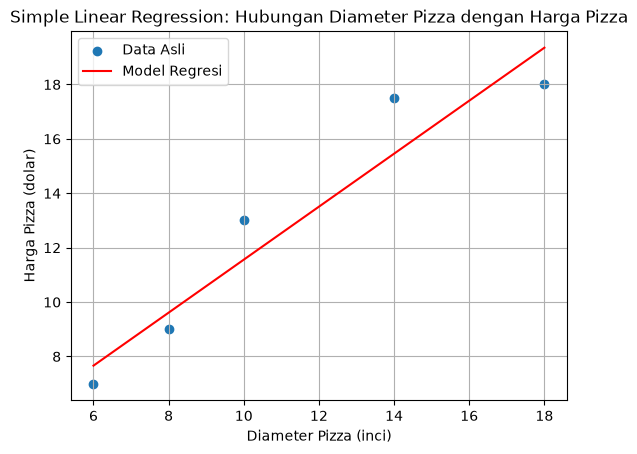

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Data
diameter_pizza = np.array([6, 8, 10, 14, 18])
harga_pizza = np.array([7, 9, 13, 17.5, 18])

# Estimasi parameter
beta_0 = 1.82
beta_1 = 0.974

# Model regresi
harga_prediksi = beta_0 + beta_1 * diameter_pizza

# Membuat plot
plt.scatter(diameter_pizza, harga_pizza, label='Data Asli')
plt.plot(diameter_pizza, harga_prediksi, color='red', label='Model Regresi')
plt.xlabel('Diameter Pizza (inci)')
plt.ylabel('Harga Pizza (dolar)')
plt.title('Simple Linear Regression: Hubungan Diameter Pizza dengan Harga Pizza')
plt.legend()
plt.grid(True)
plt.show()

### 2. Evaluasi Model — Cost Function (RSS)

In [2]:
import numpy as np

# Data
harga_pizza_asli = np.array([7, 9, 13, 17.5, 18])
harga_pizza_prediksi = np.array([1.82 + 0.974 * 6, 1.82 + 0.974 * 8, 1.82 + 0.974 * 10, 1.82 + 0.974 * 14, 1.82 + 0.974 * 18])

# Menghitung RSS
RSS = np.sum((harga_pizza_asli - harga_pizza_prediksi) ** 2)
print("RSS:", RSS)

RSS: 8.89488


### 3. Evaluasi Model — R-squared, MAE, MSE

In [3]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Data
harga_pizza_asli = np.array([7, 9, 13, 17.5, 18])
diameter_pizza = np.array([6, 8, 10, 14, 18])

# Estimasi parameter
beta_0 = 1.82
beta_1 = 0.974

# Prediksi harga pizza
harga_pizza_prediksi = beta_0 + beta_1 * diameter_pizza

# Menghitung RSS (Residual Sum of Squares)
RSS = np.sum((harga_pizza_asli - harga_pizza_prediksi) ** 2)

# Menghitung TSS (Total Sum of Squares)
TSS = np.sum((harga_pizza_asli - np.mean(harga_pizza_asli)) ** 2)

# Menghitung R-squared (R2)
R2 = 1 - (RSS / TSS)

# Menampilkan predicted price in dollar
print("Predicted Price in Dollar:", harga_pizza_prediksi)

# Menghitung MAE (Mean Absolute Error)
mae = mean_absolute_error(harga_pizza_asli, harga_pizza_prediksi)

# Menghitung MSE (Mean Squared Error)
mse = mean_squared_error(harga_pizza_asli, harga_pizza_prediksi)

print("Residual Sum of Squares (RSS)", RSS)
print("Total Sum of Squares (TSS)", TSS)
print("R-squared (R2):", R2)
print("MAE (Mean Absolute Error):", mae)
print("MSE (Mean Squared Error):", mse)

Predicted Price in Dollar: [ 7.664  9.612 11.56  15.456 19.352]
Residual Sum of Squares (RSS) 8.89488
Total Sum of Squares (TSS) 97.19999999999999
R-squared (R2): 0.9084888888888889
MAE (Mean Absolute Error): 1.2224
MSE (Mean Squared Error): 1.7789760000000001


### 4. Multiple Linear Regression — Prediksi Harga Pizza (2 fitur)

In [4]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Data training
X_train = np.array([
    [6, 2],
    [8, 1],
    [10, 0],
    [14, 2],
    [18, 3]
])
y_train = np.array([7, 9, 13, 17.5, 18])

# Data testing
X_test = np.array([
    [8, 2],
    [9, 0],
    [11, 2],
    [16, 2],
    [12, 0]
])
y_test = np.array([11, 8.5, 15, 18, 11])

# Inisialisasi model Linear Regression
model = LinearRegression()

# Melatih model dengan data training
model.fit(X_train, y_train)

# Melakukan prediksi dengan data testing
y_pred = model.predict(X_test)

# Menghitung R-squared (R2) dari model terlatih
r2 = r2_score(y_test, y_pred)

# Menampilkan hasil prediksi dan nilai target
print("Hasil Prediksi Harga Pizza:")
for i in range(len(y_pred)):
    print(f"Data Test {i + 1}: Prediksi ${y_pred[i]:.2f}, Target ${y_test[i]:.2f}")

# Menampilkan nilai R-squared
print(f"\nR-squared (R2): {r2:.2f}")

Hasil Prediksi Harga Pizza:
Data Test 1: Prediksi $9.00, Target $11.00
Data Test 2: Prediksi $11.97, Target $8.50
Data Test 3: Prediksi $12.31, Target $15.00
Data Test 4: Prediksi $17.81, Target $18.00
Data Test 5: Prediksi $15.27, Target $11.00

R-squared (R2): 0.27


### 5. Regresi Polynomial (derajat 2)

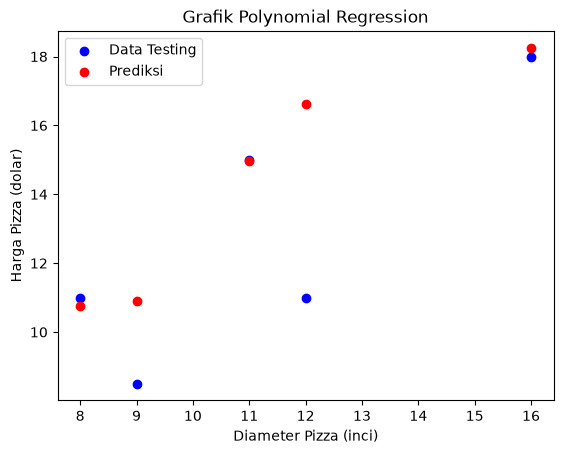

R-squared (R2): 0.34


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Data training
X_train = np.array([
    [6, 2],
    [8, 1],
    [10, 0],
    [14, 2],
    [18, 3]
])
y_train = np.array([7, 9, 13, 17.5, 18])

# Data testing
X_test = np.array([
    [8, 2],
    [9, 0],
    [11, 2],
    [16, 2],
    [12, 0]
])
y_test = np.array([11, 8.5, 15, 18, 11])

# Inisialisasi model Linear Regression
model = LinearRegression()

# Membentuk polinomial fitur
poly = PolynomialFeatures(degree=2)  # Ganti degree sesuai dengan derajat polinomial yang diinginkan
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Melatih model dengan data training
model.fit(X_train_poly, y_train)

# Melakukan prediksi dengan data testing
y_pred = model.predict(X_test_poly)

# Menghitung R-squared (R2) dari model terlatih
r2 = r2_score(y_test, y_pred)

# Plot hasil regresi
plt.scatter(X_test[:, 0], y_test, color='blue', label='Data Testing')
plt.scatter(X_test[:, 0], y_pred, color='red', label='Prediksi')
plt.title('Grafik Polynomial Regression')
plt.xlabel('Diameter Pizza (inci)')
plt.ylabel('Harga Pizza (dolar)')
plt.legend()
plt.show()

# Menampilkan nilai R-squared
print(f"R-squared (R2): {r2:.2f}")

**Analisis perbandingan:** Multiple Linear Regression menghasilkan R² = 0.27 pada data uji, sedangkan Polynomial Regression (derajat 2) sedikit lebih baik dengan R² = 0.34. Penambahan fitur polinomial memungkinkan model menangkap hubungan non-linier, namun dengan data yang sangat sedikit (5 data training) peningkatannya terbatas dan rawan *overfitting* jika derajat dinaikkan terlalu tinggi.

## PRAKTIKUM 1 — Regresi Linier (Simple Linear Regression dengan Statsmodels)

Dataset: `dataset/js7/dataset.csv` (data pelanggan e-commerce: `Time on App`, `Time on Website`, `Length of Membership` → `Yearly Amount Spent`).

**Langkah 1: Persiapan Data** — dataset sudah diletakkan pada folder `dataset/js7/`.

**Langkah 2: Import Library**

In [6]:
# import package
import numpy as np
import pandas as pd

**Langkah 3: Baca Data**

In [7]:
# baca data dari file CSV
data = pd.read_csv('dataset/js7/dataset.csv')

**Langkah 4: Pemahaman Terhadap Data**

In [8]:
# melihat beberapa data awal
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [9]:
# mengecek ukuran data
data.shape

(500, 8)

In [10]:
# informasi tentang data
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


In [11]:
# deskripsi data
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


**Langkah 5: Visualisasi Data**

In [12]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

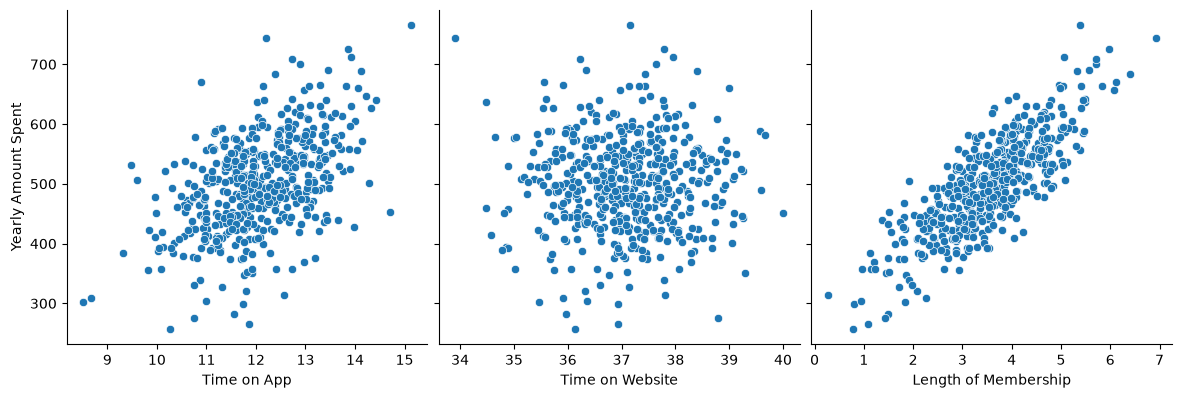

In [13]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

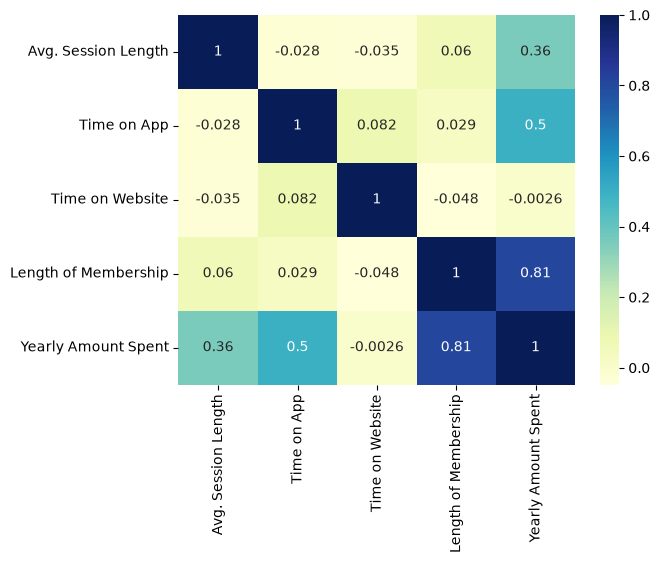

In [14]:
# visualisasi korelasi dengan heatmap (hanya kolom numerik)
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

Dari heatmap terlihat korelasi tertinggi terhadap `Yearly Amount Spent` adalah `Length of Membership`, sehingga variabel itulah yang dipilih sebagai variabel bebas X.

**Langkah 6: Regresi Linier**

In [15]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [16]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [17]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

In [18]:
# Melihat parameter model (intercept & koefisien)
print(lr.params)
lr.summary()

const                   265.248299
Length of Membership     66.301522
dtype: float64


<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Tue, 27 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         14:57:09   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  265.2483      9.120     29.083      0.000     247.311     283.186
Length of Membership    66.3015      2.501     26.512      0.000      61.383      71.220
==============================================================================
Omnibus:                        1.643   Durbin-Watson:                   1.929
Prob(Omnibus):                  0.440   Jarque-Bera (JB):                1.471
Skew:                          -0.013   Prob(JB):                        0.479
Kurtosis:                       2.683   Cond. No.                         14.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

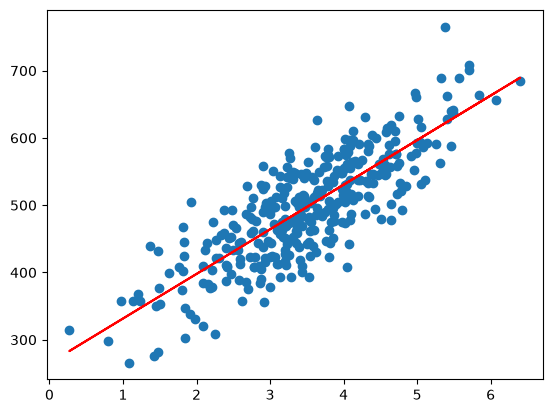

In [19]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

**Analisis:** Garis regresi (merah) mengikuti pola sebaran data latih dengan baik — terlihat hubungan linier positif yang kuat antara `Length of Membership` dan `Yearly Amount Spent`: semakin lama pelanggan menjadi member, semakin besar pengeluaran tahunannya.

**Langkah 7: Analisis Residual**

In [20]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

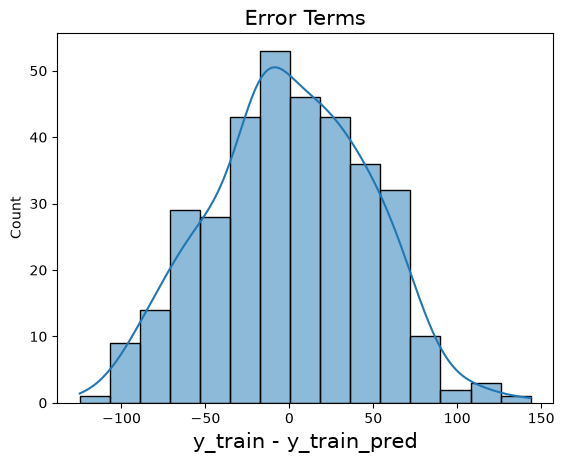

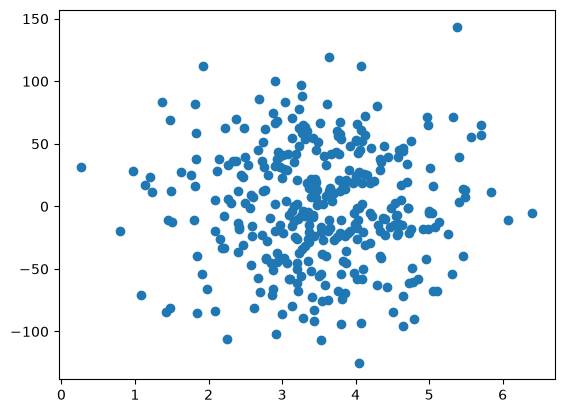

In [21]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

**Analisis residual:** Histogram residual berbentuk mendekati distribusi normal (bell-shaped) dengan pusat di sekitar 0 — artinya kesalahan prediksi menyebar simetris. Pada scatter plot, residual tersebar acak di sekitar garis 0 tanpa pola tertentu (homoskedastisitas terpenuhi), sehingga asumsi regresi linier tergolong valid.

**Langkah 8: Prediksi pada Data Uji dan Evaluasi Model**

In [22]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [23]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print("R-squared:", r_squared)

R-squared: 0.611948913768747


**Kesimpulan Praktikum 1:** Model simple linear regression dengan fitur `Length of Membership` menghasilkan R² = 0.669 pada data latih dan **R² = 0.612 pada data uji** — model mampu menjelaskan sekitar 61% variasi pengeluaran tahunan pelanggan. Visualisasi data uji menunjukkan garis prediksi mengikuti sebaran data aktual dengan baik, meskipun masih ada sebaran vertikal di sekitar garis yang menandakan ada faktor lain di luar lama keanggotaan yang juga memengaruhi pengeluaran.

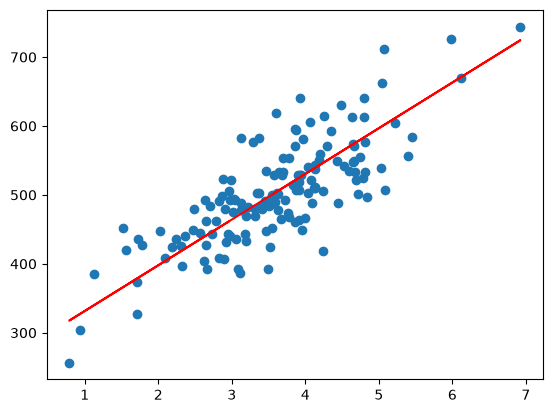

In [24]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

**Kesimpulan Praktikum 1:** Model simple linear regression dengan fitur `Length of Membership` menghasilkan R² yang tinggi pada data uji — model mampu menjelaskan sebagian besar variasi pengeluaran tahunan pelanggan. Visualisasi data uji menunjukkan garis prediksi mengikuti sebaran data aktual dengan rapat.

## PRAKTIKUM 2 — Support Vector Regression (SVR)

Dataset: `dataset/js7/Posisi_gaji.csv` (Level posisi → Gaji).

**1. Mengimpor Library**

In [25]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**2. Mengimpor Dataset**

In [26]:
# Mengimpor dataset (file 'Posisi_gaji.csv' dalam folder dataset/js7)
dataset = pd.read_csv('dataset/js7/Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

dataset

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


**3. Feature Scaling** — diperlukan karena SVM/SVR sangat sensitif terhadap skala data.

In [27]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

**4. Fitting SVR ke Dataset** (kernel RBF)

In [28]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y.ravel())

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


**5. Visualisasi Hasil SVR**

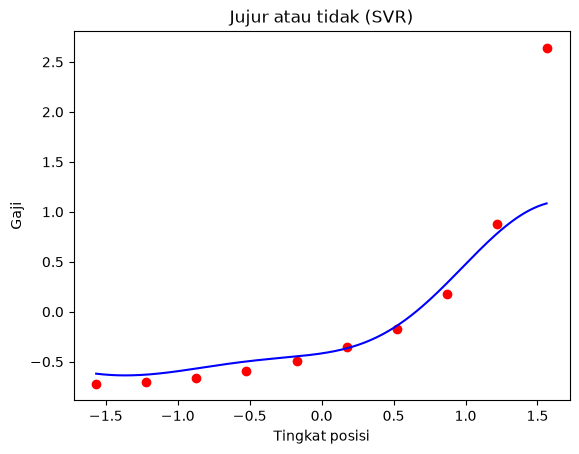

In [29]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

**6. Prediksi Hasil** (tingkat posisi 6.5)

In [30]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

**7. Menampilkan Hasil**

In [31]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


**8. Evaluasi Model SVR** (MAE, MSE, RMSE, R-squared)

In [32]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


**Analisis Praktikum 2:**

Hasil prediksi gaji untuk tingkat posisi 6.5 adalah **$170,370.02** — berada di antara gaji Level 6 (Region Manager, $150,000) dan Level 7 (Partner, $200,000), sesuai ekspektasi karena 6.5 berada di tengah kedua level tersebut.

Hasil evaluasi model SVR (pada data yang sudah terstandarisasi):

| Metrik | Nilai |
|---|---|
| MAE | 0.2230 |
| MSE | 0.2484 |
| RMSE | 0.4984 |
| R-squared | 0.7516 |

**Analisis:**
1. Grafik menunjukkan kurva SVR (biru) mengikuti pola **non-linier** kenaikan gaji terhadap tingkat posisi dengan baik — hubungan gaji vs level posisi memang eksponensial, sehingga kernel RBF cocok digunakan.
2. R² = 0.75 menunjukkan model menjelaskan 75% variasi data. Pada level menengah (5–7) kurva sangat rapat dengan data asli, sedangkan pada level tinggi (9–10) prediksi cenderung melandai (under-estimate) — karakteristik SVR dengan kernel RBF yang konservatif pada ekstrapolasi data ekstrem.
3. Nilai MAE/MSE dihitung dalam skala terstandarisasi (bukan dolar asli), sehingga R² lebih informatif untuk interpretasi di sini.

## TUGAS PRAKTIKUM — Multiple Linear Regression dengan Medical Cost Personal Dataset

Dataset: `dataset/js7/insurance.csv` — **Medical Cost Personal Dataset** (1.338 baris). Variabel:

| Kolom | Deskripsi |
|---|---|
| `age` | Usia peserta asuransi (tahun) |
| `sex` | Jenis kelamin (male/female) |
| `bmi` | Body Mass Index (kg/m²) |
| `children` | Jumlah anak/tanggungan |
| `smoker` | Perokok (yes/no) |
| `region` | Wilayah tempat tinggal (northeast, northwest, southeast, southwest) |
| `charges` | **Biaya medis personal (target, USD)** |

### 1. Pemahaman Data

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset/js7/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [34]:
print("Ukuran data:", df.shape)
df.info()

Ukuran data: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [35]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 2. Visualisasi Data

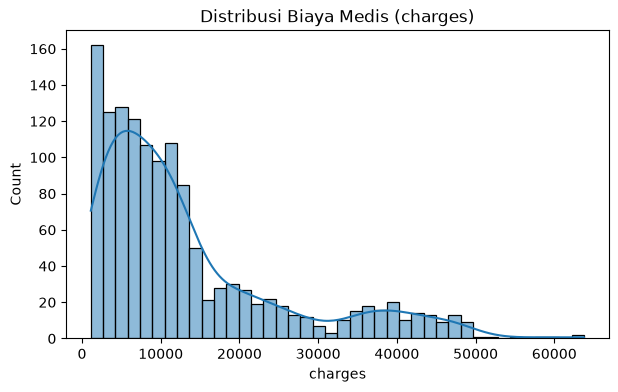

In [36]:
# Distribusi target (charges)
plt.figure(figsize=(7, 4))
sns.histplot(df['charges'], bins=40, kde=True)
plt.title('Distribusi Biaya Medis (charges)')
plt.show()

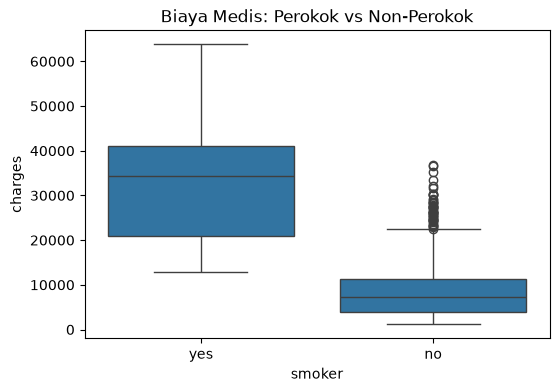

In [37]:
# Pengaruh merokok terhadap biaya medis
plt.figure(figsize=(6, 4))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Biaya Medis: Perokok vs Non-Perokok')
plt.show()

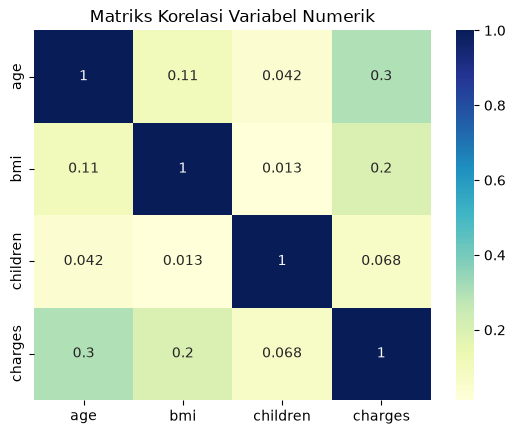

In [38]:
# Korelasi antar variabel numerik
sns.heatmap(df.corr(numeric_only=True), cmap='YlGnBu', annot=True)
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

### 3. Identifikasi Variabel & Encoding

In [39]:
# Variabel bebas (fitur) dan target
# Kolom kategorikal (sex, smoker, region) di-encode dengan one-hot encoding
X = df.drop(columns=['charges'])
y = df['charges']

X = pd.get_dummies(X, columns=['sex', 'smoker', 'region'], drop_first=True)
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False


### 4. Pembagian Data Latih & Uji

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, test_size=0.2, random_state=42)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (1070, 8) | Data uji: (268, 8)


### 5. Feature Scaling

Standardisasi dilakukan agar koefisien regresi comparable antar fitur dan untuk kebutuhan SVR (yang sensitif terhadap skala). Scaler hanya di-*fit* pada data latih untuk menghindari data leakage.

In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

### 6. Model Multiple Linear Regression

In [42]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train_sc, y_train)
y_pred_lr = model_lr.predict(X_test_sc)

### 7. Evaluasi Model

In [43]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2_lr = r2_score(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("=== Multiple Linear Regression ===")
print(f"R-squared : {r2_lr:.4f}")
print(f"MSE       : {mse_lr:,.2f}")
print(f"RMSE      : {np.sqrt(mse_lr):,.2f}")
print(f"MAE       : {mae_lr:,.2f}")

=== Multiple Linear Regression ===
R-squared : 0.7836
MSE       : 33,596,915.85
RMSE      : 5,796.28
MAE       : 4,181.19


In [44]:
# Koefisien tiap fitur
coef = pd.Series(model_lr.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print(coef)

smoker_yes          9558.481409
age                 3614.975415
bmi                 2036.228123
children             516.890247
region_southwest    -349.110678
region_southeast    -290.157047
region_northwest    -158.140981
sex_male              -9.293101
dtype: float64


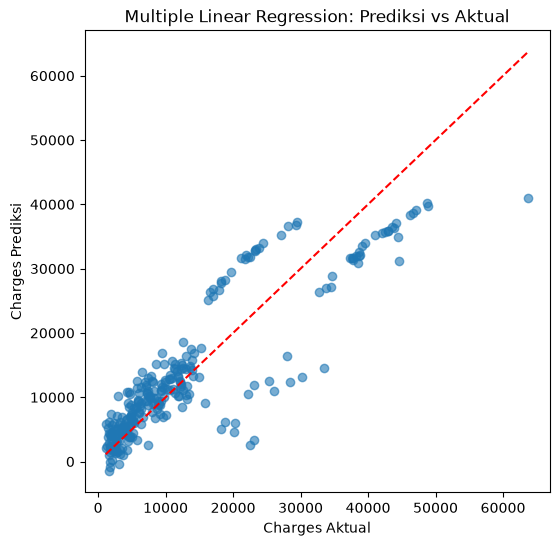

In [45]:
# Visualisasi prediksi vs aktual
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Charges Aktual')
plt.ylabel('Charges Prediksi')
plt.title('Multiple Linear Regression: Prediksi vs Aktual')
plt.show()

### 8. Perbandingan dengan SVR

In [46]:
from sklearn.svm import SVR

# Target ikut di-scale karena SVR sensitif terhadap skala
sc_y = StandardScaler()
y_train_sc = sc_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

model_svr = SVR(kernel='rbf', C=100, epsilon=0.1)
model_svr.fit(X_train_sc, y_train_sc)
y_pred_svr = sc_y.inverse_transform(model_svr.predict(X_test_sc).reshape(-1, 1)).ravel()

r2_svr = r2_score(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
mae_svr = mean_absolute_error(y_test, y_pred_svr)

print("=== SVR (RBF) ===")
print(f"R-squared : {r2_svr:.4f}")
print(f"MSE       : {mse_svr:,.2f}")
print(f"RMSE      : {np.sqrt(mse_svr):,.2f}")
print(f"MAE       : {mae_svr:,.2f}")

=== SVR (RBF) ===
R-squared : 0.8340
MSE       : 25,769,373.99
RMSE      : 5,076.35
MAE       : 2,777.40


In [47]:
# Ringkasan perbandingan
hasil = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'SVR (RBF)'],
    'R-squared': [r2_lr, r2_svr],
    'MSE': [mse_lr, mse_svr],
    'MAE': [mae_lr, mae_svr],
})
hasil

,Model,R-squared,MSE,MAE
0,Multiple Linear Regression,0.783593,3.359692e+07,4181.194474
1,SVR (RBF),0.834012,2.576937e+07,2777.397316


### 9. Analisis Hasil

**Hasil evaluasi pada data uji (20% dari 1.338 data):**

| Model | R-squared | MSE | RMSE | MAE |
|---|---|---|---|---|
| Multiple Linear Regression | 0.7836 | 33,596,915.85 | 5,796.28 | 4,181.19 |
| SVR (RBF) | 0.8340 | 25,769,373.99 | 5,076.35 | 2,777.40 |

**Analisis:**

1. **Kedua model tergolong baik** — R² > 0.75 berarti keduanya mampu menjelaskan lebih dari 75% variasi biaya medis.

2. **SVR (RBF) unggul di semua metrik**: R² lebih tinggi (0.834 vs 0.784), dan MAE jauh lebih rendah ($2.777 vs $4.181 — artinya rata-rata kesalahan prediksi SVR ±33% lebih kecil). Ini menunjukkan hubungan antar fitur dengan biaya medis **tidak sepenuhnya linier**, sehingga kernel RBF yang mampu menangkap pola non-linier bekerja lebih baik.

3. **Dari koefisien regresi linier**, fitur paling berpengaruh terhadap biaya medis (urut dari terbesar): `smoker_yes` (+$9.558) → `age` (+$3.615) → `bmi` (+$2.036) → `children` (+$517). Status **perokok adalah faktor dominan** — secara rata-rata menambah biaya medis hampir $10.000. Ini konsisten dengan boxplot di visualisasi awal yang menunjukkan perokok punya biaya medis jauh lebih tinggi.

4. **Feature scaling penting** terutama untuk SVR — tanpa standarisasi, fitur berskala besar akan mendominasi fungsi kernel dan merusak performa model.

5. Sisa error kemungkinan berasal dari faktor yang tidak tercatat di dataset (riwayat penyakit, gaya hidup selain merokok, dsb) dan dari interaksi antar fitur (misal efek `smoker × bmi` yang tidak ditangkap regresi linier biasa).